In [8]:
import pandas as pd
import matplotlib.pyplot as plt

In [9]:
concat = pd.read_parquet("/home/dev/projects/data/concat/CONCAT.parquet")

In [10]:
mets = pd.read_parquet('/home/dev/projects/data/case1_run5/outputs/forecasts/source_div0case1_run5/NBEATSEnsemble_2023-09-18_item_metrics.parquet')[["item_id", "NRMSE", "MASE", "sMAPE"]]
mets.sort_values("NRMSE", ascending=False).head(50)

,item_id,NRMSE,MASE,sMAPE
3722,T46193_kaggle,inf,inf,1.999428
2925,T22621_kaggle,inf,inf,1.980825
4931,T89975_kaggle,inf,inf,1.928904
4702,T79409_kaggle,2999.577528,9385.523569,1.995371
2841,T20264_kaggle,242.427528,142.168934,1.934826
3417,T36778_kaggle,237.180026,132.292375,0.495772
2537,T14220_kaggle,167.804576,90.962096,1.326737
4540,T725_kaggle,84.394064,31.944537,1.159657
716,HOUSEHOLD_1_032_TX_1_validation_m5,74.254779,415.842433,1.985806
4442,T69446_kaggle,45.997685,56.043212,1.430948


In [11]:
series = "T70007_kaggle"

In [12]:
forecasts = pd.read_parquet("/home/dev/projects/data/case1_run5/outputs/forecasts/source_div0case1_run5/NBEATSEnsemble_2023-09-24_forecast.parquet")
forecast = forecasts[forecasts["item_id"] == series]
forecast

,item_id,start_date,fcst_step,fcst_step_date,sample_fcst0,sample_fcst1,sample_fcst2,sample_fcst3,sample_fcst4,sample_fcst5
index,,,,,,,,,,
0,T70007_kaggle,2023-09-24,1,2023-09-24,2895.915039,4826.917969,3469.660889,4093.155029,3621.977783,3905.130859
1,T70007_kaggle,2023-09-24,2,2023-10-01,3464.862305,3464.466553,3912.129395,3829.243164,3251.285156,3675.664795
2,T70007_kaggle,2023-09-24,3,2023-10-08,3445.009033,4312.373047,3779.336426,3879.934814,3679.662109,3780.763916
3,T70007_kaggle,2023-09-24,4,2023-10-15,2723.117920,4374.811523,3406.695801,3838.733643,3557.060791,3704.059082
4,T70007_kaggle,2023-09-24,5,2023-10-22,3396.667969,2371.375488,3340.416992,3689.239258,3700.475586,3545.048828
5,T70007_kaggle,2023-09-24,6,2023-10-29,3714.039307,4146.870117,3671.662354,3616.358398,3343.425537,3453.852783
6,T70007_kaggle,2023-09-24,7,2023-11-05,3467.737061,5745.750977,3483.587402,3592.768066,3549.879639,3744.597412
7,T70007_kaggle,2023-09-24,8,2023-11-12,3285.585449,3267.623535,3625.089600,3460.837891,3162.624268,3411.011719
8,T70007_kaggle,2023-09-24,9,2023-11-19,3379.400391,3115.250244,3504.582764,3663.421143,3796.385742,3239.841309


In [13]:

truth = concat[concat["id_ts"] == series]
truth["Date"] = pd.to_datetime(truth["Date"])

/tmp/ipykernel_350204/243096320.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  truth["Date"] = pd.to_datetime(truth["Date"])


/tmp/ipykernel_350204/1814653370.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  forecast["fcst_step_date"] = pd.to_datetime(forecast["fcst_step_date"])


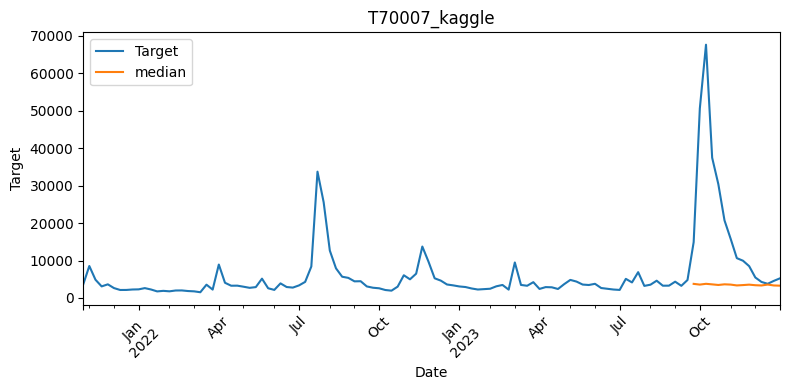

In [14]:
df_truth = truth.copy()
df_truth.set_index("Date", inplace=True)
df_truth = df_truth[df_truth.index >= "2021-01-01"]

forecast["fcst_step_date"] = pd.to_datetime(forecast["fcst_step_date"])

fcst = forecast.copy()
fcst["median"] = fcst.filter(regex="sample").median(axis=1)
fcst = fcst.drop(columns=["item_id", "start_date", "fcst_step"])
fcst = fcst.drop(columns=fcst.filter(regex="sample").columns)
fcst.rename(columns={"fcst_step_date": "Date"}, inplace=True)
fcst.set_index("Date", inplace=True)

aligned = df_truth[["Target"]].join(fcst[["median"]], how="left")

aligned.plot(figsize=(8, 4))
plt.xlabel("Date")
plt.ylabel("Target")
plt.title(series)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()